# M87 reconstruction experiments

This notebook is a small imaging laboratory. It intentionally leaves out the globe, animation, and widgets from `UV instantaneous.ipynb`, so we can work on reconstruction without breaking the original.

**Flow:** telescope locations → one UV snapshot → sampled Fourier data → dirty images and beams → later CLEAN.

## 1. Make one fixed UV snapshot

These are the current EHT station locations and the parts of the UV math we need. Change `SNAPSHOT_TIME_UTC` later to compare a different instant.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from datetime import datetime, timezone
from itertools import combinations

# name, latitude (degrees), longitude (degrees), altitude (m)
station_data = [
    ('ALMA', -23.03217, -67.75536, 5043), ('APEX', -23.00572, -67.75928, 5061),
    ('GLT', 76.535087, -68.685908, 67), ('IRAM', 37.066145, -3.392597, 2864),
    ('JCMT', 19.82293, -155.47709, 4074), ('KP', 31.953279, -111.614806, 1927),
    ('LMT', 18.98575, -97.31481, 4618), ('NOEMA', 44.63366, 5.90669, 2554),
    ('SMA', 19.8241, -155.47823, 4075), ('SMT', 32.7016, -109.8913, 3173),
    ('SPT', -90.0, 45.0, 2820),
    # Proposed / future locations from the original notebook.
    ('JELM', 41.096991, -105.976692, 2943), ('GLTS', 72.579967, -38.449163, 3229),
    ('HESS', -23.27154, 16.5002, 1900), ('HOR', -3.139078, 37.438599, 3726),
    ('LAS', -29.031711, -70.685063, 2321), ('BAJA', 31.043898, -115.463636, 2802),
    ('CNI', 28.299309, -16.508709, 2364),
]
FITS_PATH = '/Users/nishaadshah/Downloads/M87_230GHz.fits'
SOURCE_RA_DEG, SOURCE_DEC_DEG = 187.70593, 12.39112  # M87*
WAVELENGTH_M = 1.3e-3
MIN_ELEVATION_DEG = 15.0
SNAPSHOT_TIME_UTC = datetime(2026, 4, 11, 0, 0, tzinfo=timezone.utc)

WGS84_A_M, WGS84_F = 6_378_137.0, 1 / 298.257223563
WGS84_E2 = WGS84_F * (2 - WGS84_F)

def geodetic_to_ecef(lat_deg, lon_deg, altitude_m):
    lat, lon = np.radians([lat_deg, lon_deg])
    radius = WGS84_A_M / np.sqrt(1 - WGS84_E2 * np.sin(lat) ** 2)
    return np.array([(radius + altitude_m) * np.cos(lat) * np.cos(lon),
                     (radius + altitude_m) * np.cos(lat) * np.sin(lon),
                     (radius * (1 - WGS84_E2) + altitude_m) * np.sin(lat)])

def local_up_ecef(lat_deg, lon_deg):
    lat, lon = np.radians([lat_deg, lon_deg])
    return np.array([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)])

def gmst_radians(time_utc):
    jd = time_utc.timestamp() / 86400 + 2440587.5
    t = (jd - 2451545.0) / 36525.0
    return np.radians((280.46061837 + 360.98564736629 * (jd - 2451545.0) + 0.000387933*t**2 - t**3/38710000) % 360)

def ecef_to_eci(vector, time_utc):
    theta = gmst_radians(time_utc)
    return np.array([[np.cos(theta), -np.sin(theta), 0], [np.sin(theta), np.cos(theta), 0], [0, 0, 1]]) @ vector

def source_vector(ra_deg, dec_deg):
    ra, dec = np.radians([ra_deg, dec_deg])
    return np.array([np.cos(dec)*np.cos(ra), np.cos(dec)*np.sin(ra), np.sin(dec)])

station_ecef = [geodetic_to_ecef(lat, lon, altitude) for _, lat, lon, altitude in station_data]
station_up = [local_up_ecef(lat, lon) for _, lat, lon, _ in station_data]


In [2]:
def calculate_uv_at_time(time_utc):
    target = source_vector(SOURCE_RA_DEG, SOURCE_DEC_DEG)
    u_axis = np.cross([0.0, 0.0, 1.0], target); u_axis /= np.linalg.norm(u_axis)
    v_axis = np.cross(target, u_axis); v_axis /= np.linalg.norm(v_axis)
    elevations = [np.degrees(np.arcsin(np.clip(np.dot(ecef_to_eci(up, time_utc), target), -1, 1))) for up in station_up]
    visible = [elevation >= MIN_ELEVATION_DEG for elevation in elevations]
    u, v, pairs = [], [], []
    for i, j in combinations(range(len(station_data)), 2):
        if not (visible[i] and visible[j]):
            continue
        baseline = ecef_to_eci(station_ecef[j] - station_ecef[i], time_utc)
        u_value = np.dot(baseline, u_axis) / WAVELENGTH_M / 1e9
        v_value = np.dot(baseline, v_axis) / WAVELENGTH_M / 1e9
        u.extend([u_value, -u_value]); v.extend([v_value, -v_value])  # conjugate pair
        pairs.append(f'{station_data[i][0]}–{station_data[j][0]}')
    return np.array(u), np.array(v), pairs

sample_u_raw, sample_v_raw, usable_baselines = calculate_uv_at_time(SNAPSHOT_TIME_UTC)
print(f'{SNAPSHOT_TIME_UTC:%Y-%m-%d %H:%M UTC}: {len(usable_baselines)} baselines / {len(sample_u_raw)} UV points')


2026-04-11 00:00 UTC: 45 baselines / 90 UV points


## 2. Load the actual image and sample its Fourier transform


In [3]:
with fits.open(FITS_PATH) as hdul:
    reference_image = np.asarray(hdul[0].data, dtype=float)
    header = hdul[0].header

pixel_scale_rad = np.deg2rad(abs(header['CDELT1']))
height, width = reference_image.shape
fourier_image = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(reference_image)))
u_axis_glambda = np.fft.fftshift(np.fft.fftfreq(width, d=pixel_scale_rad)) / 1e9
v_axis_glambda = np.fft.fftshift(np.fft.fftfreq(height, d=pixel_scale_rad)) / 1e9

def sample_fourier_at_uv(raw_u, raw_v):
    # The u reversal matches the FITS RA-axis convention in the original notebook.
    u, v = -np.asarray(raw_u), np.asarray(raw_v)
    x = (u - u_axis_glambda[0]) / (u_axis_glambda[1] - u_axis_glambda[0])
    y = (v - v_axis_glambda[0]) / (v_axis_glambda[1] - v_axis_glambda[0])
    x0, y0 = np.floor(x).astype(int), np.floor(y).astype(int)
    fx, fy = x - x0, y - y0
    valid = (x0 >= 0) & (x0 < width - 1) & (y0 >= 0) & (y0 < height - 1)
    values = np.full(len(u), np.nan + 1j*np.nan)
    bottom = (1-fx[valid])*fourier_image[y0[valid], x0[valid]] + fx[valid]*fourier_image[y0[valid], x0[valid]+1]
    top = (1-fx[valid])*fourier_image[y0[valid]+1, x0[valid]] + fx[valid]*fourier_image[y0[valid]+1, x0[valid]+1]
    values[valid] = (1-fy[valid])*bottom + fy[valid]*top
    return u, v, values

sample_u, sample_v, visibilities = sample_fourier_at_uv(sample_u_raw, sample_v_raw)
print(f'{np.count_nonzero(np.isfinite(visibilities))} Fourier samples fall inside the image UV grid.')


90 Fourier samples fall inside the image UV grid.


## 3. Compare square bins with occupancy-normalized Gaussian gridding

For the Gaussian case we blur the **sum** of visibility values and the **sampling count**, then divide them. This is the key change from the original notebook:

`normalized UV value = blurred visibility sum / (blurred occupancy + epsilon)`

The Gaussian width is in Gλ, then converted to cells. That makes it less tied to an arbitrary grid resolution.

In [4]:
def normalize_for_display(image):
    peak = np.max(np.abs(image))
    return image / peak if peak else image

def inverse_fourier_image(grid):
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(grid))).real

def grid_visibility_sums(u, v, values):
    sums = np.zeros_like(fourier_image, dtype=complex)
    counts = np.zeros_like(reference_image, dtype=float)
    x = np.rint((u-u_axis_glambda[0]) / (u_axis_glambda[1]-u_axis_glambda[0])).astype(int)
    y = np.rint((v-v_axis_glambda[0]) / (v_axis_glambda[1]-v_axis_glambda[0])).astype(int)
    valid = np.isfinite(values) & (x >= 0) & (x < width) & (y >= 0) & (y < height)
    np.add.at(sums, (y[valid], x[valid]), values[valid])
    np.add.at(counts, (y[valid], x[valid]), 1)
    return sums, counts

def gaussian_blur(array, sigma_cells):
    radius = max(1, int(np.ceil(3*sigma_cells)))
    position = np.arange(-radius, radius+1)
    kernel = np.exp(-0.5*(position/sigma_cells)**2); kernel /= kernel.sum()
    padded = np.pad(array, ((radius, radius), (radius, radius)), mode='constant')
    horizontal = np.apply_along_axis(lambda row: np.convolve(row, kernel, mode='valid'), 1, padded)
    return np.apply_along_axis(lambda column: np.convolve(column, kernel, mode='valid'), 0, horizontal)

def gaussian_normalized_grid(sums, counts, sigma_glambda, epsilon):
    sigma_cells = sigma_glambda / abs(u_axis_glambda[1] - u_axis_glambda[0])
    blurred_sum = gaussian_blur(sums.real, sigma_cells) + 1j*gaussian_blur(sums.imag, sigma_cells)
    blurred_occupancy = gaussian_blur(counts, sigma_cells)
    grid = np.divide(blurred_sum, blurred_occupancy + epsilon, out=np.zeros_like(blurred_sum), where=blurred_occupancy > epsilon)
    return grid, blurred_occupancy, sigma_cells


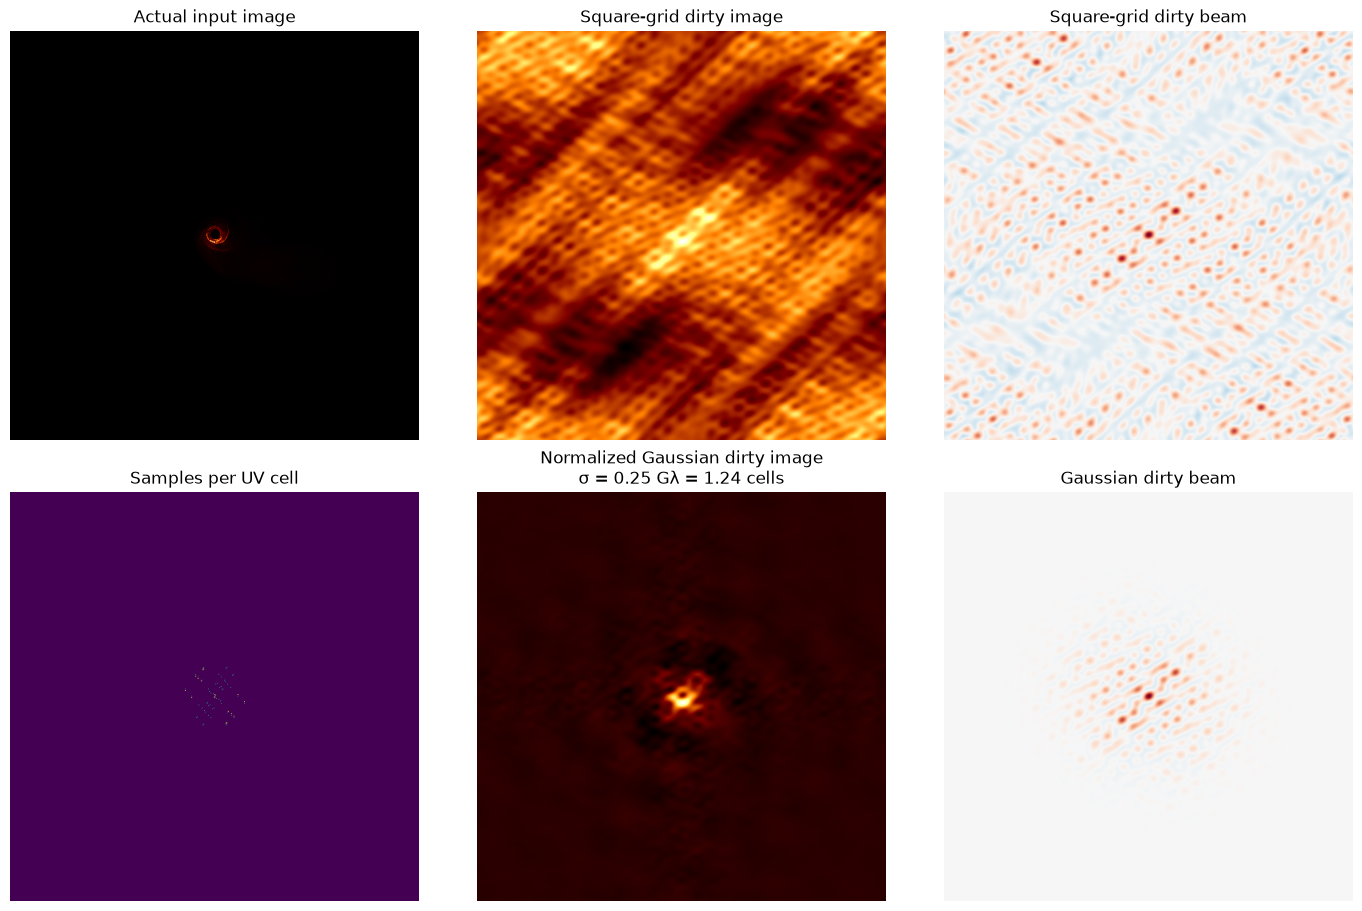

73 occupied UV cells; Gaussian σ = 1.24 grid cells


In [5]:
sums, counts = grid_visibility_sums(sample_u, sample_v, visibilities)
square_grid = np.divide(sums, counts, out=np.zeros_like(sums), where=counts > 0)
square_dirty_image = inverse_fourier_image(square_grid)
square_dirty_beam = normalize_for_display(inverse_fourier_image((counts > 0).astype(float)))

SIGMA_GLAMBDA = 0.25
EPSILON = 1e-8
gaussian_grid, gaussian_occupancy, sigma_cells = gaussian_normalized_grid(sums, counts, SIGMA_GLAMBDA, EPSILON)
gaussian_dirty_image = inverse_fourier_image(gaussian_grid)
gaussian_dirty_beam = normalize_for_display(inverse_fourier_image(gaussian_occupancy))

panels = [(reference_image, 'Actual input image', 'afmhot'),
          (square_dirty_image, 'Square-grid dirty image', 'afmhot'),
          (square_dirty_beam, 'Square-grid dirty beam', 'RdBu_r'),
          (counts, 'Samples per UV cell', 'viridis'),
          (gaussian_dirty_image, f'Normalized Gaussian dirty image\nσ = {SIGMA_GLAMBDA:.2f} Gλ = {sigma_cells:.2f} cells', 'afmhot'),
          (gaussian_dirty_beam, 'Gaussian dirty beam', 'RdBu_r')]
fig, axes = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
for ax, (image, title, cmap) in zip(axes.flat, panels):
    if 'beam' in title.lower():
        limit = np.max(np.abs(image)); ax.imshow(image, origin='lower', cmap=cmap, vmin=-limit, vmax=limit)
    else:
        ax.imshow(normalize_for_display(image), origin='lower', cmap=cmap)
    ax.set_title(title); ax.set_axis_off()
plt.show()
print(f'{np.count_nonzero(counts)} occupied UV cells; Gaussian σ = {sigma_cells:.2f} grid cells')


## 4. CLEAN reconstruction



In [ ]:
def shift_without_wrap(image, shift_y, shift_x):
    """Shift an image while filling anything that leaves the frame with zero."""
    shifted = np.zeros_like(image)
    height, width = image.shape
    source_y0, source_y1 = max(0, -shift_y), min(height, height - shift_y)
    source_x0, source_x1 = max(0, -shift_x), min(width, width - shift_x)
    destination_y0, destination_y1 = max(0, shift_y), min(height, height + shift_y)
    destination_x0, destination_x1 = max(0, shift_x), min(width, width + shift_x)
    shifted[destination_y0:destination_y1, destination_x0:destination_x1] = image[source_y0:source_y1, source_x0:source_x1]
    return shifted
#start with dirty beam that is twice as large as the dirty image, so that we can shift it around without wrapping
#make sure its bigger dimensions at beginning. Add major and minor loops. and try to select the center only
def clean_dirty_image(dirty_image, dirty_beam, loop_gain=0.1, max_iterations=250, threshold=None):
    """Basic Hogbom CLEAN for a real-valued dirty image and dirty beam."""
    residual = dirty_image.astype(float).copy()
    components = np.zeros_like(residual)
    beam_center_y, beam_center_x = np.unravel_index(np.argmax(np.abs(dirty_beam)), dirty_beam.shape)
    if threshold is None:
        threshold = 0.02 * np.max(np.abs(dirty_image))

    peak_history = []
    for _ in range(max_iterations):
        peak_y, peak_x = np.unravel_index(np.argmax(np.abs(residual)), residual.shape)
        peak_value = residual[peak_y, peak_x]
        if abs(peak_value) < threshold:
            break
        component_value = loop_gain * peak_value
        components[peak_y, peak_x] += component_value
        shifted_beam = shift_without_wrap(dirty_beam, peak_y - beam_center_y, peak_x - beam_center_x)
        residual -= component_value * shifted_beam
        peak_history.append(peak_value)

    return components, residual, np.asarray(peak_history)

def restore_clean_components(components, sigma_cells=1.5):
    """Convolve clean components with a centered, unit-peak Gaussian restoring beam."""
    delta = np.zeros_like(components)
    center_y, center_x = np.array(components.shape) // 2
    delta[center_y, center_x] = 1.0
    restoring_beam = gaussian_blur(delta, sigma_cells)
    restoring_beam /= restoring_beam[center_y, center_x]
    restored_components = gaussian_blur(components, sigma_cells) / gaussian_blur(delta, sigma_cells)[center_y, center_x]
    return restored_components, restoring_beam


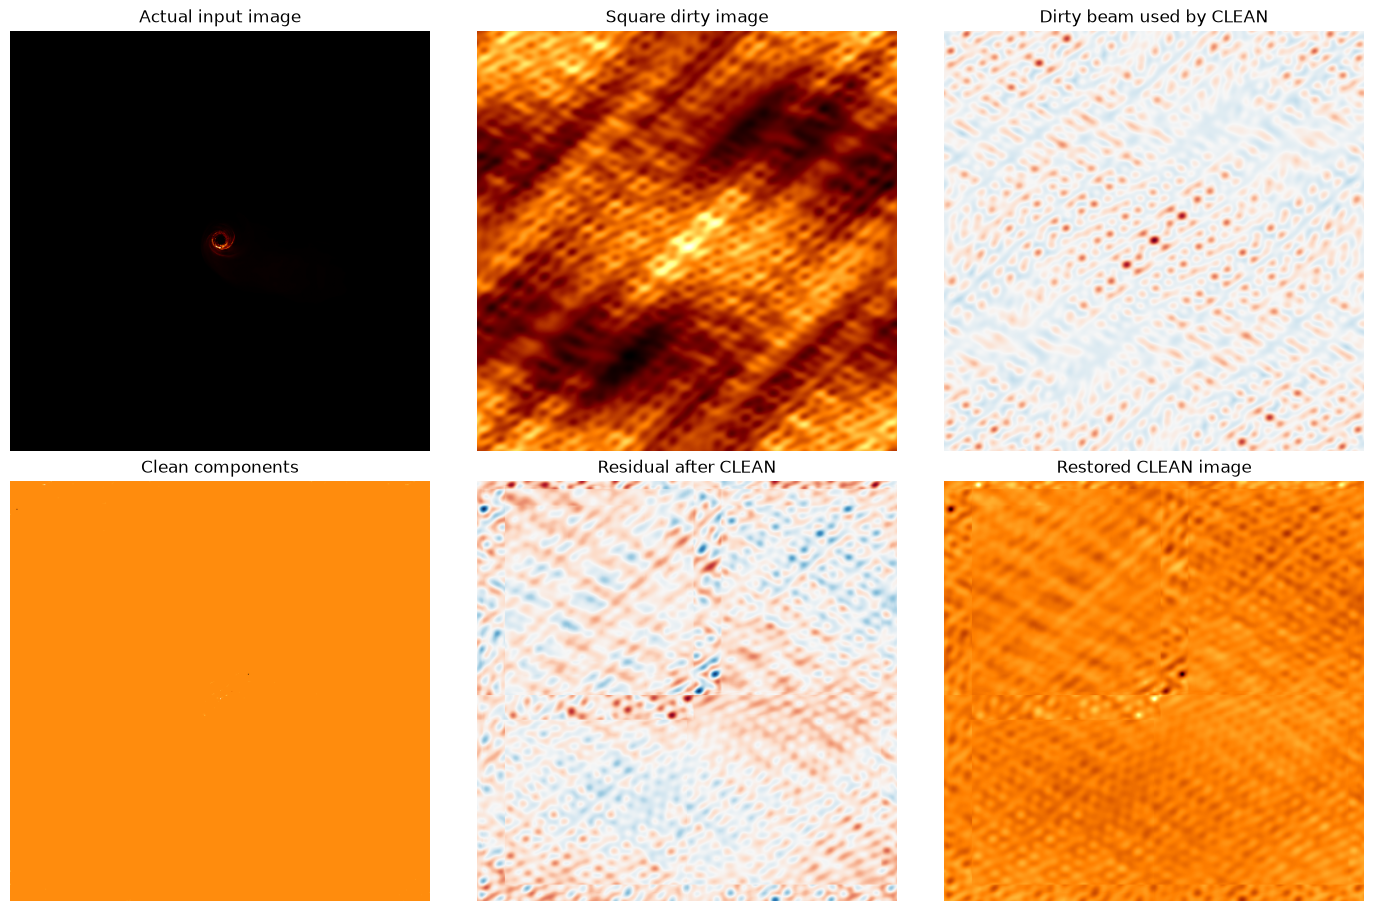

CLEAN made 250 components (gain=0.1, threshold=1.29e-06).


In [ ]:
# Keep the image and beam paired. Start with square, then try 'gaussian'.
CLEAN_INPUT = 'square'
if CLEAN_INPUT == 'square':
    clean_input_image, clean_input_beam = square_dirty_image, square_dirty_beam
elif CLEAN_INPUT == 'gaussian':
    clean_input_image, clean_input_beam = gaussian_dirty_image, gaussian_dirty_beam
else:
    raise ValueError("CLEAN_INPUT must be 'square' or 'gaussian'")

LOOP_GAIN = 0.10
MAX_ITERATIONS = 250
STOPPING_THRESHOLD = 0.02 * np.max(np.abs(clean_input_image))
#too aggressive of a stopping threshold can lead to over-cleaning and artifacts. A more conservative threshold may yield better results.
RESTORING_BEAM_SIGMA_CELLS = 1.5

clean_components, clean_residual, clean_peak_history = clean_dirty_image(
    clean_input_image, clean_input_beam, loop_gain=LOOP_GAIN,
    max_iterations=MAX_ITERATIONS, threshold=STOPPING_THRESHOLD,
)
restored_components, restoring_beam = restore_clean_components(
    clean_components, sigma_cells=RESTORING_BEAM_SIGMA_CELLS,
)
clean_restored_image = restored_components + clean_residual

fig, axes = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
clean_panels = [(reference_image, 'Actual input image', 'afmhot'),
                (clean_input_image, f'{CLEAN_INPUT.title()} dirty image', 'afmhot'),
                (clean_input_beam, 'Dirty beam used by CLEAN', 'RdBu_r'),
                (clean_components, 'Clean components', 'afmhot'),
                (clean_residual, 'Residual after CLEAN', 'RdBu_r'),
                (clean_restored_image, 'Restored CLEAN image', 'afmhot')]
for ax, (image, title, cmap) in zip(axes.flat, clean_panels):
    if 'beam' in title.lower() or 'residual' in title.lower():
        limit = np.max(np.abs(image)); ax.imshow(image, origin='lower', cmap=cmap, vmin=-limit, vmax=limit)
    else:
        ax.imshow(normalize_for_display(image), origin='lower', cmap=cmap)
    ax.set_title(title); ax.set_axis_off()
plt.show()
print(f'CLEAN made {len(clean_peak_history)} components (gain={LOOP_GAIN}, threshold={STOPPING_THRESHOLD:.3g}).')


### What to try next

- Start with `CLEAN_INPUT = 'square'`. After that, switch to `'gaussian'` and compare the restored images.
- Lower `LOOP_GAIN` if the reconstruction looks unstable; increase `MAX_ITERATIONS` if the residual remains strong.
- The Gaussian restoring beam is a simple first choice. Later, you can choose its width from the central lobe of the dirty beam.